# v5 – Without same-wall cases

The sixth model version. It repeats [v4](v4_ensembles.ipynb) exactly (the same four candidates, grids, folds and selection rule) but leaves out every case with both windows in the same wall.

![Flow of v5_no_same_wall](images/v5_no_same_wall_flow.png)

**How to read it:** grey is the data, blue the training on the development data (the training cases on different walls), orange the prediction and the scores on the test cases on different walls. The vertical arrow is what training hands over: the pipeline of the selected model, refitted on all development data. Steps with a thick border and a tag are new in this version.

| | v4 | v5 |
|---|---|---|
| Layouts | all three | only `opposite_walls` and `adjacent_walls` |
| Development data | 432 training cases | 399 (33 same-wall cases left out) |
| Test data | 109 test cases, 93 with t90 | 101 (8 same-wall cases left out), 92 with t90 |
| What the model covers | every setup | only windows on **different walls** |
| Candidates, grids, folds, selection metric | Ridge, tree, random forest, gradient boosting; MAE of log(τ) | the same |

Why: in v4 the three largest test errors were all same-wall cases. They are a different kind of flow (both openings on the wind side, no cross-ventilation), they come from the other simulation method (B), and there are only 41 of them. v5 shows how well a model does on windows on different walls when it learns only from those.

The column meanings are in [results/README.md](../results/README.md).

## 1) Setup

In [1]:
from pathlib import Path
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error
from sklearn.model_selection import GridSearchCV, KFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeRegressor

VERSION = "v5_no_same_wall"
RANDOM_STATE = 42
LN10 = np.log(10)  # t90 = ln(10) * tau, see v1

DATA_PATH = Path("../results/dataset_550/dataset_550.csv")
RESULTS_DIR = Path("results")
print("Data file:", DATA_PATH, "| found:", DATA_PATH.exists())

Data file: ../results/dataset_550/dataset_550.csv | found: True


## 2) Load the data and split it

The same data and the same split as in every version (v0, sections 2 and 3). The training cases are the **development data**: models are fitted, compared and tuned only on them. The test cases stay untouched until section 5.

The split is made on all cases as before; the same-wall cases are left out afterwards (section 2.1). So the test cases of v5 are those of v4 without the same-wall ones, and v4 can be scored on exactly the same cases.

In [2]:
df = pd.read_csv(DATA_PATH)
df = df[df["status"] == "ok"].set_index("case_id")

TARGET_COL = "t90_s"
# Only values that are fixed before a simulation starts (same choice as in unit 2)
FEATURE_COLS = [
    "layout",
    "window1_x_m",
    "window1_mode",
    "window1_angle_deg",
    "window1_hinge",
    "window2_x_m",
    "window2_mode",
    "window2_angle_deg",
    "window2_hinge",
    "wind_speed_ms",
]

print("Simulations:", len(df))
print("Missing input values:", int(df[FEATURE_COLS].isna().sum().sum()))

t90_reached = df[TARGET_COL].notna()
display(pd.crosstab(
    df["layout"],
    t90_reached.map({True: "t90 reached", False: "t90 > 600 s"}),
    margins=True,
    margins_name="total",
))

Simulations: 541
Missing input values: 0


t90_s,t90 > 600 s,t90 reached,total
layout,,,
adjacent_walls,22,228,250
opposite_walls,20,230,250
same_wall,34,7,41
total,76,465,541


In [3]:
strata = df["layout"] + " / " + np.where(t90_reached, "reached", "not reached")

train_df, test_df = train_test_split(
    df,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=strata,
)

print("Training simulations:", len(train_df))
print("Test simulations:    ", len(test_df))
display(pd.crosstab(test_df["layout"], test_df[TARGET_COL].notna().map({True: "t90 reached", False: "t90 > 600 s"})))

Training simulations: 432
Test simulations:     109


t90_s,t90 > 600 s,t90 reached
layout,,
adjacent_walls,5,46
opposite_walls,4,46
same_wall,7,1


### 2.1 Only in v5: leave out the same-wall cases

In [4]:
n_train_before, n_test_before = len(train_df), len(test_df)
train_df = train_df[train_df["layout"] != "same_wall"]
test_df = test_df[test_df["layout"] != "same_wall"]

print(f"Training cases: {n_train_before} -> {len(train_df)}")
print(f"Test cases:     {n_test_before} -> {len(test_df)}, of which {test_df[TARGET_COL].notna().sum()} with t90")
display(pd.crosstab(train_df["layout"], train_df[TARGET_COL].notna().map({True: "t90 reached", False: "t90 > 600 s"})))

Training cases: 432 -> 399
Test cases:     109 -> 101, of which 92 with t90


t90_s,t90 > 600 s,t90 reached
layout,,
adjacent_walls,17,182
opposite_walls,16,184


In [5]:
TAU_COL = "tau_s"

X_dev, y_dev = train_df[FEATURE_COLS], np.log(train_df[TAU_COL])
X_test, y_test = test_df[FEATURE_COLS], np.log(test_df[TAU_COL])

print("Development data:", X_dev.shape, y_dev.shape)
print("Test data:       ", X_test.shape, y_test.shape)

Development data: (399, 10) (399,)
Test data:        (101, 10) (101,)


As in v1 and v2, the target is log(τ). All scores below are therefore scores of log(τ):

- an **MAE of log(τ)** of 0.22 means that τ is typically off by a factor of exp(0.22) ≈ 1.25, i.e. about 25 %;
- RMSE and R² are computed on log(τ) as well.

This MAE is the metric that selects the model. It was fixed before the tuning: a relative error counts the same for fast and for slow cases, and it uses every case.

## 3) Preprocessing and cross-validation

As in v3 and v4. The preprocessing is that of v2: log(wind speed), standardised numeric inputs, one-hot encoded categorical inputs. Our inputs have no missing values, so there is no imputer.

For the cross-validation two things are fixed:

- `KFold` splits the development data into 5 parts, the *folds*. The model is trained 5 times; each fold is the validation data once, while the other 4 folds are used for training.
- `regression_scoring` lists the scores computed in every run. Its keys (`mae`, …) name the entries in the result of `cross_validate`.

| Parameter | Meaning |
|---|---|
| `n_splits=5` | number of folds, and so the number of training runs |
| `shuffle=True` | mixes the rows before the folds are made |
| `random_state=42` | makes the mixing, and so the folds, reproducible |

The whole pipeline is fitted anew in every fold, so the log, the scaling and the one-hot categories are learned from that fold's training part only.

In [6]:
num_cols = X_dev.select_dtypes(include="number").columns.tolist()
cat_cols = [col for col in FEATURE_COLS if col not in num_cols]
WIND_COL = "wind_speed_ms"
other_num_cols = [col for col in num_cols if col != WIND_COL]


def build_preprocessor():
    log_wind = Pipeline(steps=[
        ("log", FunctionTransformer(np.log, feature_names_out=lambda transformer, names: ["log_wind_speed"])),
        ("scale", StandardScaler()),
    ])
    return ColumnTransformer(
        transformers=[
            ("wind", log_wind, [WIND_COL]),
            ("num", StandardScaler(), other_num_cols),
            ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
        ],
        remainder="drop",
        verbose_feature_names_out=False,
    )


regression_cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE,
)

regression_scoring = {
    "mae": "neg_mean_absolute_error",
    "rmse": "neg_root_mean_squared_error",
    "r2": "r2",
}

print("Numeric inputs:    ", len(num_cols))
print("Categorical inputs:", len(cat_cols))

Numeric inputs:     5
Categorical inputs: 5


## 4) Tune and compare the candidates

### 4.1 The candidates

| Model | Idea | Tuned settings |
|---|---|---|
| **Ridge** | linear model with a penalty on large coefficients (v0–v3) | `alpha`: strength of the penalty |
| **DecisionTree** | one tree of yes/no questions about the inputs (v0–v3) | `max_depth`, `min_samples_leaf`: the grid of unit 4 |
| **RandomForest** | many deep trees, each grown on a random resample of the training cases and with a random subset of the inputs at each split. The forest predicts their **average**, which smooths the steps of a single tree and reduces overfitting. | `max_depth`, `min_samples_leaf`, `max_features`: share of the inputs tried at each split |
| **GradientBoosting** | many small trees built **one after another**: each new tree corrects the remaining errors of the trees before it, scaled down by the `learning_rate`. A small learning rate needs more trees. | `n_estimators`: number of trees, `learning_rate`, `max_depth` of each tree |

Each candidate gets a `GridSearchCV` with the same folds as in v3. `scoring=regression_scoring` records MAE, RMSE and R² for every combination; `refit="mae"` makes the MAE of log(τ) the score that selects. The random forest has 300 trees; the random choices of both ensembles are fixed by `random_state`.

The candidates and their grids are exactly those of v4, including its extended gradient-boosting grid.

In [7]:
def pipeline_with(model):
    return Pipeline(steps=[
        ("preprocess", build_preprocessor()),
        ("model", model),
    ])


candidates = {
    "Ridge": (
        Ridge(),
        {"model__alpha": [0.01, 0.1, 1.0, 10.0, 100.0]},
    ),
    "DecisionTree": (
        DecisionTreeRegressor(random_state=RANDOM_STATE),
        {"model__max_depth": [3, 5, 8, None], "model__min_samples_leaf": [1, 3, 5, 10]},
    ),
    "RandomForest": (
        RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE),
        {
            "model__max_depth": [8, 12, None],
            "model__min_samples_leaf": [1, 2, 4],
            "model__max_features": [0.33, 0.5, 1.0],
        },
    ),
    "GradientBoosting": (
        GradientBoostingRegressor(random_state=RANDOM_STATE),
        {
            "model__n_estimators": [300, 1000, 2000],
            "model__learning_rate": [0.02, 0.05, 0.1],
            "model__max_depth": [2, 3, 4, 5, 6],
        },
    ),
}

searches = {}
for name, (model, grid) in candidates.items():
    start = time.time()
    searches[name] = GridSearchCV(
        estimator=pipeline_with(model),
        param_grid=grid,
        scoring=regression_scoring,
        refit="mae",
        cv=regression_cv,
        n_jobs=-1,
        return_train_score=True,
    ).fit(X_dev, y_dev)
    n_combinations = len(searches[name].cv_results_["params"])
    print(f"{name:17s} {n_combinations:3d} combinations x 5 folds in {time.time() - start:5.1f} s")

Ridge               5 combinations x 5 folds in   0.8 s


DecisionTree       16 combinations x 5 folds in   0.3 s


RandomForest       27 combinations x 5 folds in   5.9 s


GradientBoosting   45 combinations x 5 folds in  32.8 s


### 4.2 Comparison

For each candidate, the row shows its best combination. The baseline is cross-validated with the same folds, as in v3.

In [8]:
baseline_cv = cross_validate(
    pipeline_with(DummyRegressor(strategy="median")),
    X_dev,
    y_dev,
    cv=regression_cv,
    scoring=regression_scoring,
    return_train_score=True,
)

rows = [{
    "model": "Baseline (median)",
    "best settings": "–",
    "training MAE": -baseline_cv["train_mae"].mean(),
    "CV MAE": -baseline_cv["test_mae"].mean(),
    "CV MAE std": baseline_cv["test_mae"].std(),
    "CV RMSE": -baseline_cv["test_rmse"].mean(),
    "CV R²": baseline_cv["test_r2"].mean(),
}]
for name, search in searches.items():
    i, r = search.best_index_, search.cv_results_
    rows.append({
        "model": name,
        "best settings": ", ".join(f"{k.removeprefix('model__')}={v}" for k, v in search.best_params_.items()),
        "training MAE": -r["mean_train_mae"][i],
        "CV MAE": -r["mean_test_mae"][i],
        "CV MAE std": r["std_test_mae"][i],
        "CV RMSE": -r["mean_test_rmse"][i],
        "CV R²": r["mean_test_r2"][i],
    })

comparison = pd.DataFrame(rows).set_index("model").sort_values("CV MAE")
comparison["typical τ error"] = (np.exp(comparison["CV MAE"]) - 1).map("{:.0%}".format)
display(comparison.round(3))

,best settings,training MAE,CV MAE,CV MAE std,CV RMSE,CV R²,typical τ error
model,,,,,,,
GradientBoosting,"learning_rate=0.1, max_depth=3, n_estimators=300",0.023,0.138,0.016,0.179,0.946,15%
RandomForest,"max_depth=12, max_features=1.0, min_samples_le...",0.071,0.163,0.019,0.213,0.924,18%
DecisionTree,"max_depth=8, min_samples_leaf=3",0.087,0.206,0.024,0.277,0.871,23%
Ridge,alpha=10.0,0.212,0.217,0.008,0.255,0.891,24%
Baseline (median),–,0.638,0.640,0.032,0.782,-0.007,90%


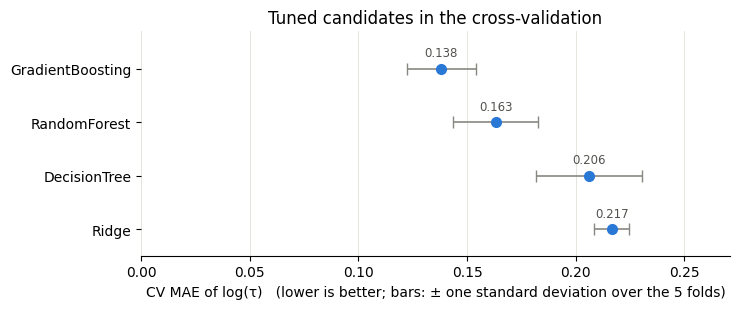

In [9]:
tuned = comparison.drop(index="Baseline (median)").sort_values("CV MAE", ascending=False)

fig, ax = plt.subplots(figsize=(7.5, 3.2))
ax.errorbar(
    tuned["CV MAE"], tuned.index, xerr=tuned["CV MAE std"],
    fmt="o", color="#2a78d6", ecolor="#898781", elinewidth=1.2, capsize=4, markersize=7,
)
for value, name in zip(tuned["CV MAE"], tuned.index):
    ax.annotate(f"{value:.3f}", (value, name), textcoords="offset points", xytext=(0, 9),
                ha="center", fontsize=8.5, color="#52514e")
ax.set_xlim(0, tuned["CV MAE"].max() + tuned["CV MAE std"].max() + 0.03)
ax.set_ylim(-0.5, len(tuned) - 0.3)  # room for the value labels above the top point
ax.set_xlabel("CV MAE of log(τ)   (lower is better; bars: ± one standard deviation over the 5 folds)")
ax.grid(axis="x", color="#e1e0d9", linewidth=0.6)
ax.set_axisbelow(True)
for side in ("top", "right", "left"):
    ax.spines[side].set_visible(False)
ax.set_title("Tuned candidates in the cross-validation")
fig.tight_layout()
plt.show()

### 4.3 Is the best setting inside the grid?

If the best value of a setting is the largest or the smallest value tried, the true optimum may lie outside the grid. The table shows, for each value of a setting, the best CV MAE over all other settings.

In [10]:
for name in ["RandomForest", "GradientBoosting"]:
    results = pd.DataFrame(searches[name].cv_results_)
    results["CV MAE"] = -results["mean_test_mae"]
    for parameter, grid_values in candidates[name][1].items():
        values = results[f"param_{parameter}"].astype(str)  # as text, so that None is kept
        best_per_value = {str(v): round(results.loc[values == str(v), "CV MAE"].min(), 4) for v in grid_values}
        print(f"{name:17s} {parameter.removeprefix('model__'):17s}", best_per_value)

RandomForest      max_depth         {'8': 0.1635, '12': 0.1631, 'None': 0.1631}
RandomForest      min_samples_leaf  {'1': 0.1633, '2': 0.1631, '4': 0.1678}
RandomForest      max_features      {'0.33': 0.1866, '0.5': 0.1668, '1.0': 0.1631}
GradientBoosting  n_estimators      {'300': 0.1381, '1000': 0.1394, '2000': 0.1394}
GradientBoosting  learning_rate     {'0.02': 0.14, '0.05': 0.14, '0.1': 0.1381}
GradientBoosting  max_depth         {'2': 0.1412, '3': 0.1381, '4': 0.1417, '5': 0.1496, '6': 0.1569}


For gradient boosting, depth 3 lies inside the grid. The best learning rate (0.1) and number of trees (300) lie at the edges of their ranges, but the result is flat there: the CV MAE is 0.138 against 0.139–0.140 for the neighbouring values, far less than the variation between the folds (0.016). A higher learning rate simply needs fewer trees. The grid is therefore kept as in v4. For the random forest, depth 12 and unlimited depth give the same result.

### 4.4 Selection

The rule, as in v3 and unit 4: **the candidate with the lowest mean CV MAE of log(τ)** is selected. Its `best_estimator_` has already been refitted on all 399 development cases.

In [11]:
selected_name = comparison.drop(index="Baseline (median)")["CV MAE"].idxmin()
selected = searches[selected_name].best_estimator_

print("Selected:", selected_name)
print("Settings:", comparison.loc[selected_name, "best settings"])
print(f"CV MAE of log(τ): {comparison.loc[selected_name, 'CV MAE']:.3f} ± {comparison.loc[selected_name, 'CV MAE std']:.3f}")

Selected: GradientBoosting
Settings: learning_rate=0.1, max_depth=3, n_estimators=300
CV MAE of log(τ): 0.138 ± 0.016


## 5) Final evaluation on the test cases

The selected pipeline is now applied to the test cases, for the first and only time in this version. The scores of unit 4 are on log(τ); the plots are those of v3.

In [12]:
y_pred = selected.predict(X_test)

test_results = pd.Series({
    "MAE of log(τ)": mean_absolute_error(y_test, y_pred),
    "RMSE of log(τ)": root_mean_squared_error(y_test, y_pred),
    "R² of log(τ)": r2_score(y_test, y_pred),
})

display(test_results.round(3).to_frame(f"test value, {selected_name}"))

,"test value, GradientBoosting"
MAE of log(τ),0.154
RMSE of log(τ),0.202
R² of log(τ),0.932


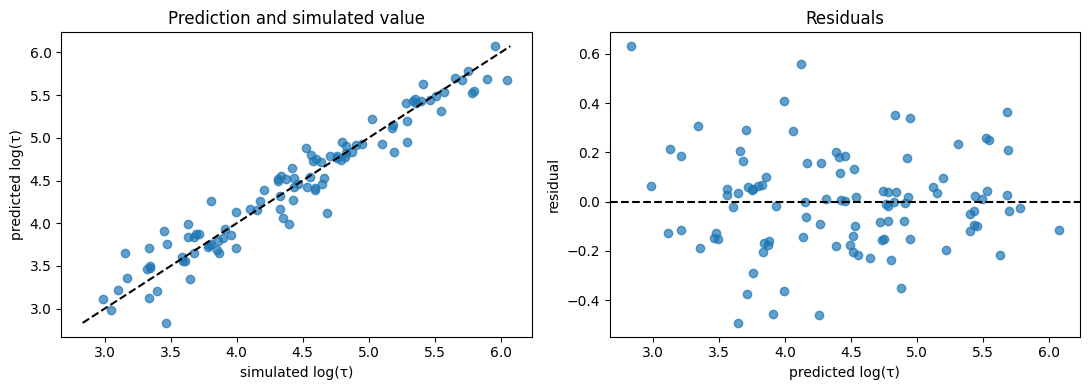

In [13]:
residuals = y_test - y_pred

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].scatter(y_test, y_pred, alpha=0.7)
limits = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
axes[0].plot(limits, limits, "--", color="black")
axes[0].set_xlabel("simulated log(τ)")
axes[0].set_ylabel("predicted log(τ)")
axes[0].set_title("Prediction and simulated value")

axes[1].scatter(y_pred, residuals, alpha=0.7)
axes[1].axhline(0, linestyle="--", color="black")
axes[1].set_xlabel("predicted log(τ)")
axes[1].set_ylabel("residual")
axes[1].set_title("Residuals")

plt.tight_layout()
plt.show()

In [14]:
# Residuals by layout: is one layout predicted systematically too fast or too slow?
display(residuals.groupby(test_df["layout"]).agg(["mean", "std", "size"]).round(3)
        .rename(columns={"mean": "mean residual", "std": "spread", "size": "n"}))

,mean residual,spread,n
layout,,,
adjacent_walls,-0.020,0.215,51
opposite_walls,0.015,0.191,50


**For the comparison with the earlier versions:** t90 = ln(10) · τ on the 92 test cases with a t90 value (the 93 of the earlier versions without their one same-wall case), and how many of the 9 test cases without t90 get a predicted t90 above 600 s. Both are only reported; nothing is selected with them.

In [15]:
has_t90 = test_df[TARGET_COL].notna()
y_test_t90 = test_df.loc[has_t90, TARGET_COL]
t90_pred = pd.Series(LN10 * np.exp(y_pred), index=X_test.index)

t90_results = pd.Series({
    "MAE [s]": mean_absolute_error(y_test_t90, t90_pred[has_t90]),
    "RMSE [s]": root_mean_squared_error(y_test_t90, t90_pred[has_t90]),
    "R²": r2_score(y_test_t90, t90_pred[has_t90]),
})
display(t90_results.round(3).to_frame(f"{selected_name}, t90 on the {has_t90.sum()}"))

slow = ~has_t90
print(f"Test cases without t90 predicted as t90 > 600 s: {(t90_pred[slow] > 600).sum()} of {slow.sum()}")
print(f"Test cases with t90 predicted as t90 > 600 s (wrong): {(t90_pred[has_t90] > 600).sum()} of {has_t90.sum()}")

earlier = pd.concat([
    pd.read_csv(RESULTS_DIR / f"{v}.csv") for v in ["v0_base", "v1_tau", "v2_log_wind", "v3_cv_tuning"]
])
display(earlier[earlier["model"] != "Mean value (reference)"][["version", "model", "MAE [s]", "R²"]].round(3))

,"GradientBoosting, t90 on the 92"
MAE [s],31.022
RMSE [s],43.914
R²,0.904


Test cases without t90 predicted as t90 > 600 s: 6 of 9
Test cases with t90 predicted as t90 > 600 s (wrong): 1 of 92


,version,model,MAE [s],R²
1,v0_base,LinearRegression,53.050,0.753
2,v0_base,Ridge,53.450,0.734
3,v0_base,DecisionTree,42.081,0.806
1,v1_tau,LinearRegression,50.206,0.713
2,v1_tau,Ridge,50.135,0.704
3,v1_tau,DecisionTree,57.922,0.638
1,v2_log_wind,LinearRegression,47.322,0.745
2,v2_log_wind,Ridge,47.252,0.736
3,v2_log_wind,DecisionTree,57.922,0.638
0,v3_cv_tuning,"DecisionTree (depth 8, leaf 1)",43.805,0.795


### Compared with v4 on the same test cases

The scores of the earlier versions above include the same-wall cases. For a fair comparison, v4's saved predictions are scored on exactly the 101 test cases of v5. Again, this is only reported.

In [16]:
v4_pred = pd.read_csv(RESULTS_DIR / "v4_ensembles_test_predictions.csv", index_col="case_id").loc[X_test.index]
v4_name = next(col for col in v4_pred if col.startswith("tau ")).removeprefix("tau ")


def same_case_scores(tau, t90):
    return {
        "MAE of log(τ)": mean_absolute_error(y_test, np.log(tau)),
        "R² of log(τ)": r2_score(y_test, np.log(tau)),
        "t90 MAE [s]": mean_absolute_error(y_test_t90, t90[has_t90]),
        "t90 RMSE [s]": root_mean_squared_error(y_test_t90, t90[has_t90]),
        "t90 R²": r2_score(y_test_t90, t90[has_t90]),
        "slow cases found": f"{(t90[slow] > 600).sum()} of {slow.sum()}",
        "false alarms": f"{(t90[has_t90] > 600).sum()} of {has_t90.sum()}",
    }


display(pd.DataFrame({
    f"v4 {v4_name} (trained with same-wall)": same_case_scores(v4_pred[f"tau {v4_name}"], v4_pred[f"t90 {v4_name}"]),
    f"v5 {selected_name} (trained without)": same_case_scores(np.exp(pd.Series(y_pred, index=X_test.index)), t90_pred),
}).round(3))

,v4 GradientBoosting (trained with same-wall),v5 GradientBoosting (trained without)
MAE of log(τ),0.145878,0.153546
R² of log(τ),0.938885,0.932275
t90 MAE [s],28.986859,31.021915
t90 RMSE [s],40.442569,43.913823
t90 R²,0.918609,0.904037
slow cases found,8 of 9,6 of 9
false alarms,0 of 92,1 of 92


## 6) What the selected model learned

`feature_importances_` gives the share of the error reduction that each input achieves in the trees. The one-hot columns of a categorical input are added up, so there is one value per input.

As in v2, tilt, a 6° angle and `hinge = none` always occur together, so the importance of tilting is shared between these inputs in some way; read their values together.

In [17]:
fitted_model = selected.named_steps["model"]
feature_names = selected.named_steps["preprocess"].get_feature_names_out()


def input_of(feature):
    if feature == "log_wind_speed":
        return "wind_speed_ms (as log)"
    return next(col for col in FEATURE_COLS if feature == col or feature.startswith(col + "_"))


if hasattr(fitted_model, "feature_importances_"):
    importances = pd.Series(fitted_model.feature_importances_, index=feature_names)
    per_input = importances.groupby(importances.index.map(input_of)).sum().sort_values(ascending=False)
    display(per_input.round(3).to_frame(f"{selected_name} importance"))
else:
    print(selected_name, "has no feature importances")

,GradientBoosting importance
window2_angle_deg,0.297
wind_speed_ms (as log),0.295
window1_angle_deg,0.180
window1_mode,0.077
window2_mode,0.058
window1_hinge,0.039
window2_hinge,0.027
window1_x_m,0.018
layout,0.005
window2_x_m,0.004


## 7) Save the results

As in the earlier versions: `results/v5_no_same_wall.csv` holds the t90 scores of the selected pipeline on the 92 test cases with t90, `results/v5_no_same_wall_test_predictions.csv` its predicted t90 and τ for the 101 test cases. `results/v5_no_same_wall_cv.csv` adds the cross-validation comparison of section 4.2.

In [18]:
model_name = f"{selected_name} ({comparison.loc[selected_name, 'best settings']})"
summary = pd.DataFrame([{
    "version": VERSION,
    "model": model_name,
    **t90_results.to_dict(),
    "target": "log(tau_s)",
    "n_train": len(X_dev),
    "n_test": len(y_test_t90),
}])
summary.to_csv(RESULTS_DIR / f"{VERSION}.csv", index=False, float_format="%.3f")

comparison.drop(columns="typical τ error").to_csv(RESULTS_DIR / f"{VERSION}_cv.csv", float_format="%.4f")

test_predictions = pd.DataFrame({
    "t90_s simulated": test_df[TARGET_COL],
    "tau_s simulated": test_df[TAU_COL],
    f"t90 {selected_name}": t90_pred,
    f"tau {selected_name}": np.exp(y_pred),
}, index=X_test.index)
test_predictions.to_csv(RESULTS_DIR / f"{VERSION}_test_predictions.csv", index_label="case_id", float_format="%.1f")
display(summary.round(3))

,version,model,MAE [s],RMSE [s],R²,target,n_train,n_test
0,v5_no_same_wall,"GradientBoosting (learning_rate=0.1, max_depth...",31.022,43.914,0.904,log(tau_s),399,92


## 8) Summary and findings

**Cross-validation** (399 development cases on different walls, MAE of log(τ)):

| Model | CV MAE | typical τ error |
|---|---|---|
| GradientBoosting (depth 3, 300 trees, learning rate 0.1) | 0.138 ± 0.016 | 15 % |
| RandomForest | 0.163 ± 0.019 | 18 % |
| DecisionTree | 0.206 ± 0.024 | 23 % |
| Ridge | 0.217 ± 0.008 | 24 % |

The order is the same as in v4, and gradient boosting is selected again, now with smaller trees. These CV errors are a little lower than in v4, but they are not comparable: v4's included the hard same-wall cases.

**Test** (once): MAE of log(τ) 0.154, R² 0.93. In t90 on the 92 test cases: **MAE 31 s, RMSE 44 s, R² 0.90**. 6 of the 9 slow test cases are recognised, with 1 false alarm. The residuals show no bias by layout (mean −0.02 and +0.02), and the largest residual is 0.63 (v4: 1.06, a same-wall case).

**Main result: leaving out the same-wall cases does not help the other cases.** On exactly the same 101 test cases, v4, which was trained with the same-wall cases, is slightly better in every score: MAE of log(τ) 0.146 vs 0.154, t90 MAE 29 vs 31 s, t90 R² 0.92 vs 0.90, and 8 instead of 6 of the 9 slow cases found. The differences are small for 101 test cases, but they all point the same way. The 33 same-wall cases do not disturb the model for the other layouts; if anything, they add information on how the angles, the window modes and the wind act.

**Also:** the layout now has almost no importance (0.005): windows on opposite walls and in a corner give practically the same τ, as already seen in v1.

**Consequence:** v4 remains the best model. It covers all three layouts and is at least as good for windows on different walls. Its weak point stays the same-wall cases themselves, and the remedy is more same-wall data, not leaving them out.

**Options for the next version (v6):**

1. Save v4's pipeline with `joblib` (second notebook of unit 4) as the current best model.
2. More same-wall training data: a new simulation run with only same-wall cases (method B, about 1.5 h each on the simulation PC).
3. Final check on `test-v1` (30 new simulations, 10 per layout) once the tracer settings are fixed (PLAN.md §9).